# Project 9: Optimizer Comparison Using a Neural Network

**Stochastic Gradient Descent (SGD) vs Adam on the Iris dataset**

Author: Hamzah Tareq Al-Qudaimi, BCA, Alliance University

| Task | What this notebook does |
|---|---|
| **Task 1** | Builds a simple neural network (4 → 16 → 8 → 3) for Iris classification |
| **Task 2** | Trains it with SGD and Adam (plus SGD with momentum as an extra baseline) |
| **Task 3** | Compares training behaviour and classification performance |

The network, backpropagation and all optimizers are written **from scratch in NumPy**, so every step of the update rules is visible. All experiments use fixed random seeds, so the results are reproducible.

## 0. Setup

In [1]:
%matplotlib inline
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report, precision_recall_fscore_support

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "figure.dpi": 110})
COLORS = {"SGD": "#2C6FBB", "Adam": "#D1495B", "SGD+Momentum": "#3A9D5D"}

## 1. Dataset and preprocessing

The Iris dataset has 150 flowers (50 per species: *setosa*, *versicolor*, *virginica*) described by four measurements in cm. 
The data is split 80/20 (120 train / 30 test), **stratified** so each class keeps the same proportion. 
Features are standardised using the **training set's** mean and standard deviation only, so nothing from the test set leaks into training.

Samples: 150 | Features: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Classes: [np.str_('setosa'), np.str_('versicolor'), np.str_('virginica')]


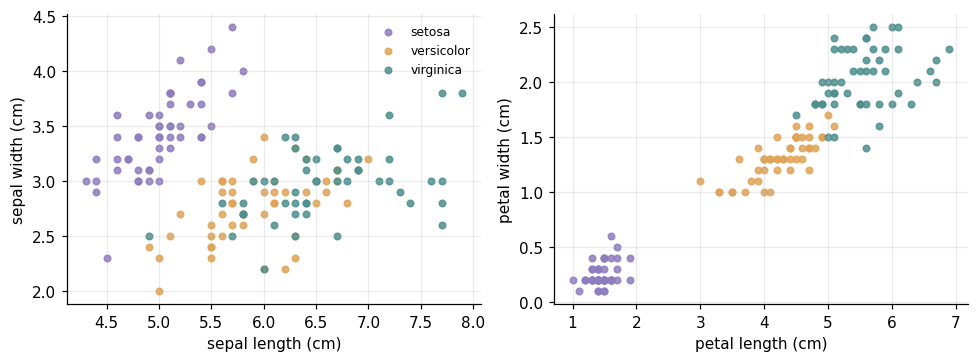

Train: (120, 4) | Test: (30, 4)
Train class counts: [40 40 40] | Test class counts: [10 10 10]


In [2]:
iris = load_iris()
print("Samples:", iris.data.shape[0], "| Features:", iris.feature_names)
print("Classes:", list(iris.target_names))

fig, axs = plt.subplots(1, 2, figsize=(9, 3.4))
cols = ["#8E7DBE", "#E0A458", "#4D908E"]
for (i, j), ax in zip([(0, 1), (2, 3)], axs):
    for c, name in enumerate(iris.target_names):
        m = iris.target == c
        ax.scatter(iris.data[m, i], iris.data[m, j], s=18, color=cols[c], label=name, alpha=0.85)
    ax.set_xlabel(iris.feature_names[i]); ax.set_ylabel(iris.feature_names[j])
axs[0].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()


def get_data(split_seed):
    X, y = iris.data, iris.target
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, stratify=y, random_state=split_seed)
    mu, sd = Xtr.mean(0), Xtr.std(0)            # statistics from the training set only
    return (Xtr - mu) / sd, (Xte - mu) / sd, ytr, yte

Xtr, Xte, ytr, yte = get_data(42)
print("Train:", Xtr.shape, "| Test:", Xte.shape)
print("Train class counts:", np.bincount(ytr), "| Test class counts:", np.bincount(yte))

## 2. Task 1: The neural network

Architecture: **4 inputs → 16 ReLU → 8 ReLU → 3 softmax outputs**, giving 4×16+16 + 16×8+8 + 8×3+3 = **243 trainable parameters**. 
Weights use He initialisation; biases start at zero.

Loss: average cross-entropy over a batch of $N$ samples, where $c_i$ is the true class of sample $i$:

$$\hat y_k = \frac{e^{z_k}}{\sum_j e^{z_j}}, \qquad L = -\frac{1}{N}\sum_{i=1}^{N}\log \hat y_{i,c_i}$$

In [3]:
LAYERS = [4, 16, 8, 3]

def init_params(rng):
    p = {}
    for i in range(len(LAYERS) - 1):
        fan_in, fan_out = LAYERS[i], LAYERS[i + 1]
        p[f"W{i+1}"] = rng.normal(0, np.sqrt(2.0 / fan_in), (fan_in, fan_out))   # He initialisation
        p[f"b{i+1}"] = np.zeros(fan_out)
    return p

def softmax(z):
    z = z - z.max(axis=1, keepdims=True)          # numerical stability
    e = np.exp(z)
    return e / e.sum(axis=1, keepdims=True)

def forward(p, X):
    z1 = X @ p["W1"] + p["b1"];  a1 = np.maximum(0, z1)
    z2 = a1 @ p["W2"] + p["b2"]; a2 = np.maximum(0, z2)
    z3 = a2 @ p["W3"] + p["b3"]; probs = softmax(z3)
    return probs, (X, z1, a1, z2, a2)

def loss_fn(probs, y):
    n = len(y)
    return -np.mean(np.log(probs[np.arange(n), y] + 1e-12))

def backward(p, cache, probs, y):
    X, z1, a1, z2, a2 = cache
    n = len(y)
    dz3 = probs.copy(); dz3[np.arange(n), y] -= 1; dz3 /= n
    g = {}
    g["W3"] = a2.T @ dz3; g["b3"] = dz3.sum(0)
    da2 = dz3 @ p["W3"].T; dz2 = da2 * (z2 > 0)
    g["W2"] = a1.T @ dz2; g["b2"] = dz2.sum(0)
    da1 = dz2 @ p["W2"].T; dz1 = da1 * (z1 > 0)
    g["W1"] = X.T @ dz1; g["b1"] = dz1.sum(0)
    return g

params = init_params(np.random.default_rng(0))
print("Total parameters:", sum(v.size for v in params.values()))

Total parameters: 243


### Gradient check

To confirm that the hand-written backpropagation is correct, compare the analytic gradients with numerical (finite-difference) gradients on randomly chosen weights from every layer. 
A relative error around $10^{-8}$ or smaller means the gradients are correct.

In [4]:
def gradient_check():
    p = init_params(np.random.default_rng(0))
    X, y = Xtr[:20], ytr[:20]
    probs, cache = forward(p, X)
    g = backward(p, cache, probs, y)
    worst, eps = 0.0, 1e-5
    rng = np.random.default_rng(1)
    for k in p:
        flat = p[k].ravel()                       # view into p[k]
        for i in rng.choice(flat.size, size=min(6, flat.size), replace=False):
            old = flat[i]
            flat[i] = old + eps; lp = loss_fn(forward(p, X)[0], y)
            flat[i] = old - eps; lm = loss_fn(forward(p, X)[0], y)
            flat[i] = old
            num, ana = (lp - lm) / (2 * eps), g[k].ravel()[i]
            worst = max(worst, abs(num - ana) / max(1e-8, abs(num) + abs(ana)))
    return worst

err = gradient_check()
print(f"Largest relative gradient error: {err:.2e}  ->", "PASS" if err < 1e-6 else "FAIL")

Largest relative gradient error: 9.21e-10  -> PASS


## 3. Task 2: The optimizers

With $\theta$ any weight, $g_t$ its gradient on a mini-batch and $\eta$ the learning rate:

**SGD:** $\theta_{t+1} = \theta_t - \eta\, g_t$

**SGD with momentum** (extra baseline, $\mu = 0.9$): $v_{t+1} = \mu v_t - \eta g_t,\quad \theta_{t+1} = \theta_t + v_{t+1}$

**Adam** ($\beta_1=0.9,\ \beta_2=0.999,\ \epsilon=10^{-8}$):

$$m_t=\beta_1 m_{t-1}+(1-\beta_1)g_t,\qquad v_t=\beta_2 v_{t-1}+(1-\beta_2)g_t^2$$
$$\hat m_t=\frac{m_t}{1-\beta_1^t},\qquad \hat v_t=\frac{v_t}{1-\beta_2^t},\qquad \theta_{t+1}=\theta_t-\eta\,\frac{\hat m_t}{\sqrt{\hat v_t}+\epsilon}$$

In [5]:
class SGD:
    def __init__(self, lr, momentum=0.0):
        self.lr, self.mu, self.v = lr, momentum, {}

    def step(self, p, g):
        for k in p:
            if self.mu > 0:
                self.v[k] = self.mu * self.v.get(k, 0) - self.lr * g[k]
                p[k] += self.v[k]
            else:
                p[k] -= self.lr * g[k]


class Adam:
    def __init__(self, lr, b1=0.9, b2=0.999, eps=1e-8):
        self.lr, self.b1, self.b2, self.eps = lr, b1, b2, eps
        self.m, self.v, self.t = {}, {}, 0

    def step(self, p, g):
        self.t += 1
        for k in p:
            self.m[k] = self.b1 * self.m.get(k, 0) + (1 - self.b1) * g[k]
            self.v[k] = self.b2 * self.v.get(k, 0) + (1 - self.b2) * g[k] ** 2
            m_hat = self.m[k] / (1 - self.b1 ** self.t)
            v_hat = self.v[k] / (1 - self.b2 ** self.t)
            p[k] -= self.lr * m_hat / (np.sqrt(v_hat) + self.eps)


def make_opt(name, lr):
    if name == "SGD":          return SGD(lr)
    if name == "SGD+Momentum": return SGD(lr, momentum=0.9)
    if name == "Adam":         return Adam(lr)
    raise ValueError(name)

### Training loop

Mini-batch training (batch size 16, 100 epochs). For a fair comparison, every optimizer in a given run starts from **identical initial weights** and sees the **same shuffling order**.

In [6]:
def evaluate(p, X, y):
    probs, _ = forward(p, X)
    return loss_fn(probs, y), float(np.mean(probs.argmax(1) == y)), probs.argmax(1)


def train(opt_name, lr, split_seed, init_seed, epochs=100, batch=16):
    Xtr, Xte, ytr, yte = get_data(split_seed)
    p = init_params(np.random.default_rng(init_seed))
    opt = make_opt(opt_name, lr)
    shuffler = np.random.default_rng(1000 + init_seed)
    hist = {k: [] for k in ["train_loss", "train_acc", "test_loss", "test_acc"]}
    t0 = time.perf_counter()
    for _ in range(epochs):
        idx = shuffler.permutation(len(ytr))
        for s in range(0, len(idx), batch):
            b = idx[s:s + batch]
            probs, cache = forward(p, Xtr[b])
            opt.step(p, backward(p, cache, probs, ytr[b]))
        trl, tra, _ = evaluate(p, Xtr, ytr)
        tel, tea, _ = evaluate(p, Xte, yte)
        hist["train_loss"].append(trl); hist["train_acc"].append(tra)
        hist["test_loss"].append(tel);  hist["test_acc"].append(tea)
    hist["time"] = time.perf_counter() - t0
    _, _, pred = evaluate(p, Xte, yte)
    hist["pred"], hist["true"] = pred, yte
    return hist


def first_epoch_below(losses, thr):
    for i, l in enumerate(losses):
        if l <= thr: return i + 1
    return None

## 4. Task 3: Comparing the results

### 4.1 Main run (learning rate 0.01, data split seed 42, initialisation seed 0)

In [7]:
LR, EPOCHS, BATCH = 0.01, 100, 16
OPTS = ["SGD", "Adam", "SGD+Momentum"]
main = {n: train(n, LR, split_seed=42, init_seed=0, epochs=EPOCHS, batch=BATCH) for n in OPTS}

rows = []
for n, h in main.items():
    rows.append({"Optimizer": n,
                 "Train loss": h["train_loss"][-1], "Test loss": h["test_loss"][-1],
                 "Train acc %": h["train_acc"][-1] * 100, "Test acc %": h["test_acc"][-1] * 100,
                 "Epochs to loss<=0.3": first_epoch_below(h["train_loss"], 0.3),
                 "Epochs to loss<=0.1": first_epoch_below(h["train_loss"], 0.1),
                 "Epochs to loss<=0.05": first_epoch_below(h["train_loss"], 0.05)})
pd.DataFrame(rows).set_index("Optimizer").round(4)

,Train loss,Test loss,Train acc %,Test acc %,Epochs to loss<=0.3,Epochs to loss<=0.1,Epochs to loss<=0.05
Optimizer,,,,,,,
SGD,0.2164,0.2652,96.6667,90.0000,59,NaN,NaN
Adam,0.0200,0.0990,99.1667,96.6667,5,10.0,20.0
SGD+Momentum,0.0324,0.0845,98.3333,96.6667,7,24.0,49.0


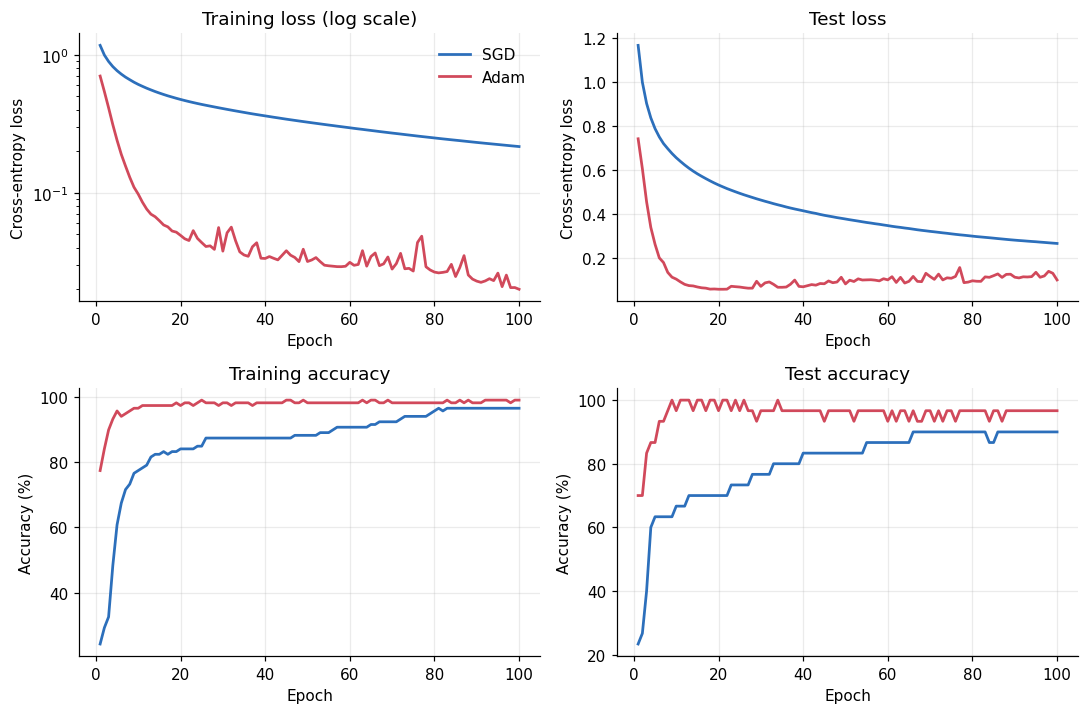

In [8]:
ep = np.arange(1, EPOCHS + 1)
fig, axs = plt.subplots(2, 2, figsize=(10, 6.6))
for n in ["SGD", "Adam"]:
    h = main[n]
    axs[0, 0].plot(ep, h["train_loss"], color=COLORS[n], label=n, lw=1.8)
    axs[0, 1].plot(ep, h["test_loss"],  color=COLORS[n], label=n, lw=1.8)
    axs[1, 0].plot(ep, np.array(h["train_acc"]) * 100, color=COLORS[n], label=n, lw=1.8)
    axs[1, 1].plot(ep, np.array(h["test_acc"]) * 100,  color=COLORS[n], label=n, lw=1.8)
axs[0, 0].set_yscale("log")
axs[0, 0].set_title("Training loss (log scale)"); axs[0, 1].set_title("Test loss")
axs[1, 0].set_title("Training accuracy");        axs[1, 1].set_title("Test accuracy")
for a in axs[0]: a.set_ylabel("Cross-entropy loss")
for a in axs[1]: a.set_ylabel("Accuracy (%)")
for a in axs.ravel(): a.set_xlabel("Epoch")
axs[0, 0].legend(frameon=False)
plt.tight_layout(); plt.show()

### 4.2 Classification performance (main run)

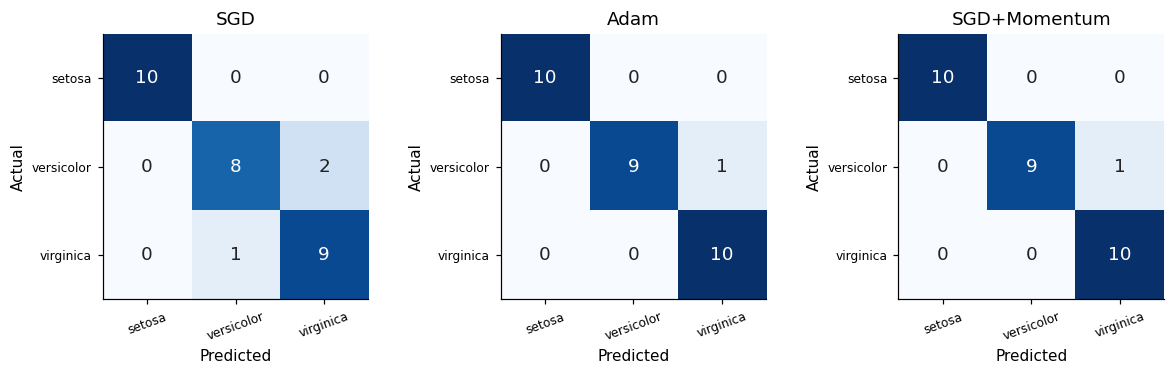

===== SGD =====
              precision    recall  f1-score   support

      setosa      1.000     1.000     1.000        10
  versicolor      0.889     0.800     0.842        10
   virginica      0.818     0.900     0.857        10

    accuracy                          0.900        30
   macro avg      0.902     0.900     0.900        30
weighted avg      0.902     0.900     0.900        30

===== Adam =====
              precision    recall  f1-score   support

      setosa      1.000     1.000     1.000        10
  versicolor      1.000     0.900     0.947        10
   virginica      0.909     1.000     0.952        10

    accuracy                          0.967        30
   macro avg      0.970     0.967     0.967        30
weighted avg      0.970     0.967     0.967        30



In [9]:
fig, axs = plt.subplots(1, 3, figsize=(11, 3.4))
for ax, n in zip(axs, OPTS):
    cm = confusion_matrix(main[n]["true"], main[n]["pred"])
    ax.imshow(cm, cmap="Blues", vmin=0, vmax=10); ax.grid(False)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > 5 else "#222", fontsize=12)
    ax.set_xticks(range(3)); ax.set_yticks(range(3))
    ax.set_xticklabels(iris.target_names, fontsize=8, rotation=20); ax.set_yticklabels(iris.target_names, fontsize=8)
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual"); ax.set_title(n)
plt.tight_layout(); plt.show()

for n in ["SGD", "Adam"]:
    print(f"===== {n} =====")
    print(classification_report(main[n]["true"], main[n]["pred"], target_names=iris.target_names, digits=3))

### 4.3 Robustness: 20 runs with different splits and initialisations

A single run can be lucky or unlucky, and with only 30 test samples one flower is worth 3.3 percentage points. 
So the experiment is repeated 20 times, each time with a different train/test split and different initial weights.

In [10]:
N_RUNS = 20
multi = {n: [train(n, LR, split_seed=s, init_seed=s, epochs=EPOCHS, batch=BATCH) for s in range(N_RUNS)] for n in OPTS}

def arr(n, key): return np.array([r[key][-1] for r in multi[n]])

summary = pd.DataFrame({
    n: {"Test acc % (mean)": arr(n, "test_acc").mean() * 100, "Test acc % (SD)": arr(n, "test_acc").std() * 100,
        "Test acc % (min)": arr(n, "test_acc").min() * 100,   "Test acc % (max)": arr(n, "test_acc").max() * 100,
        "Train acc % (mean)": arr(n, "train_acc").mean() * 100,
        "Train loss (mean)": arr(n, "train_loss").mean(),      "Test loss (mean)": arr(n, "test_loss").mean(),
        "Epochs to loss<=0.1 (mean, runs that reached it)": np.mean([e for e in (first_epoch_below(r["train_loss"], 0.1) for r in multi[n]) if e] or [np.nan]),
        "Runs that reached loss<=0.1": sum(first_epoch_below(r["train_loss"], 0.1) is not None for r in multi[n])}
    for n in OPTS}).round(3)
summary

,SGD,Adam,SGD+Momentum
Test acc % (mean),93.833,96.167,97.167
Test acc % (SD),5.403,4.252,3.693
Test acc % (min),83.333,86.667,90.000
Test acc % (max),100.000,100.000,100.000
Train acc % (mean),93.833,99.250,98.750
Train loss (mean),0.206,0.020,0.036
Test loss (mean),0.213,0.158,0.089
"Epochs to loss<=0.1 (mean, runs that reached it)",NaN,14.500,25.750
Runs that reached loss<=0.1,0.000,20.000,20.000


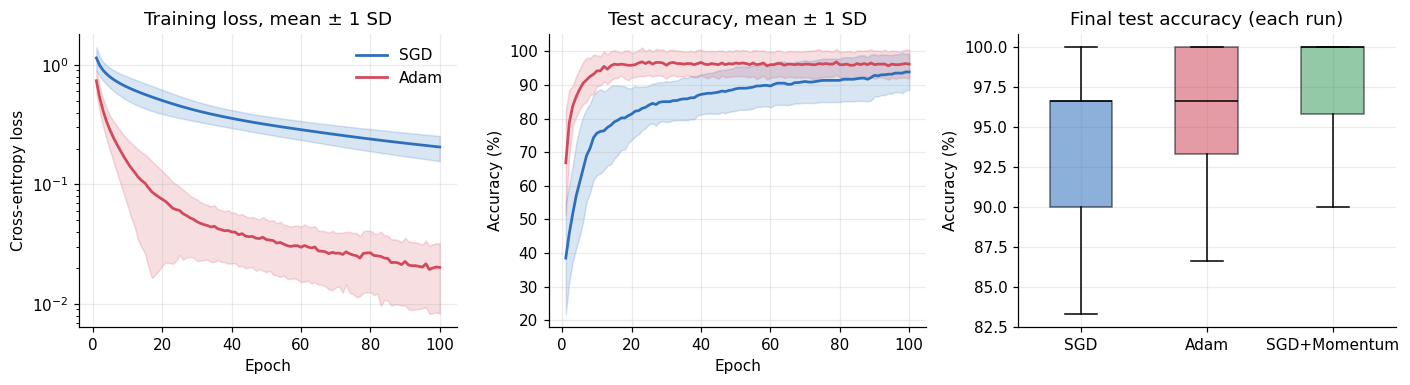

In [11]:
fig, axs = plt.subplots(1, 3, figsize=(13, 3.6))
for n in ["SGD", "Adam"]:
    for ax, key, scale in [(axs[0], "train_loss", 1), (axs[1], "test_acc", 100)]:
        A = np.array([r[key] for r in multi[n]]) * scale
        mu, sd = A.mean(0), A.std(0)
        ax.plot(ep, mu, color=COLORS[n], label=n, lw=1.8)
        ax.fill_between(ep, mu - sd, mu + sd, color=COLORS[n], alpha=0.18)
axs[0].set_yscale("log"); axs[0].set_title("Training loss, mean ± 1 SD"); axs[0].set_ylabel("Cross-entropy loss")
axs[1].set_title("Test accuracy, mean ± 1 SD"); axs[1].set_ylabel("Accuracy (%)")
for a in axs[:2]: a.set_xlabel("Epoch")
axs[0].legend(frameon=False)

data = [arr(n, "test_acc") * 100 for n in OPTS]
bp = axs[2].boxplot(data, tick_labels=OPTS, patch_artist=True, widths=0.5, medianprops=dict(color="black"))
for patch, n in zip(bp["boxes"], OPTS): patch.set_facecolor(COLORS[n]); patch.set_alpha(0.55)
axs[2].set_title("Final test accuracy (each run)"); axs[2].set_ylabel("Accuracy (%)")
plt.tight_layout(); plt.show()

In [12]:
# Paired statistical tests (same split & initialisation for both optimizers in each run)
def paired(a, b, key):
    x, y = arr(a, key), arr(b, key)
    return (x - y).mean(), stats.ttest_rel(x, y).pvalue

tests = []
for a, b in [("Adam", "SGD"), ("SGD+Momentum", "SGD"), ("Adam", "SGD+Momentum")]:
    for key in ["train_loss", "test_loss", "test_acc"]:
        d, p = paired(a, b, key)
        tests.append({"Comparison": f"{a} vs {b}", "Metric": key, "Mean difference": d, "p-value": p,
                      "Significant (p<0.05)": "yes" if p < 0.05 else "no"})
pd.DataFrame(tests).round(4)

,Comparison,Metric,Mean difference,p-value,Significant (p<0.05)
0,Adam vs SGD,train_loss,-0.1856,0.0000,yes
1,Adam vs SGD,test_loss,-0.0555,0.2050,no
2,Adam vs SGD,test_acc,0.0233,0.0896,no
3,SGD+Momentum vs SGD,train_loss,-0.1703,0.0000,yes
4,SGD+Momentum vs SGD,test_loss,-0.1235,0.0001,yes
5,SGD+Momentum vs SGD,test_acc,0.0333,0.0174,yes
6,Adam vs SGD+Momentum,train_loss,-0.0153,0.0000,yes
7,Adam vs SGD+Momentum,test_loss,0.0681,0.0147,yes
8,Adam vs SGD+Momentum,test_acc,-0.0100,0.0553,no


In [13]:
# Per-class metrics pooled over all 20 runs (600 test predictions per optimizer)
rows = []
for n in OPTS:
    yt = np.concatenate([r["true"] for r in multi[n]]); yp = np.concatenate([r["pred"] for r in multi[n]])
    p, r_, f, _ = precision_recall_fscore_support(yt, yp)
    for i, c in enumerate(iris.target_names):
        rows.append({"Optimizer": n, "Class": c, "Precision": p[i], "Recall": r_[i], "F1": f[i]})
pd.DataFrame(rows).round(3)

,Optimizer,Class,Precision,Recall,F1
0,SGD,setosa,1.000,1.000,1.000
1,SGD,versicolor,0.945,0.865,0.903
2,SGD,virginica,0.876,0.950,0.911
3,Adam,setosa,1.000,0.990,0.995
4,Adam,versicolor,0.928,0.960,0.943
5,Adam,virginica,0.959,0.935,0.947
6,SGD+Momentum,setosa,1.000,0.995,0.997
7,SGD+Momentum,versicolor,0.946,0.970,0.958
8,SGD+Momentum,virginica,0.969,0.950,0.960


### 4.4 Sensitivity to the learning rate

All comparisons above use $\eta = 0.01$, a common default for Adam but small for plain SGD. 
To see how much that choice matters, each optimizer is trained at six learning rates (10 runs each). 

*Note: this study reports test accuracy to show sensitivity. It is not a fair way to **select** a learning rate, which should be done on a separate validation set.*

,SGD,Adam,SGD+Momentum
learning rate,,,
0.001,74.0,93.7,92.3
0.003,83.7,95.3,95.0
0.010,93.0,95.0,96.3
0.030,95.7,95.3,96.0
0.100,96.0,95.3,95.3
0.300,96.0,80.3,71.3


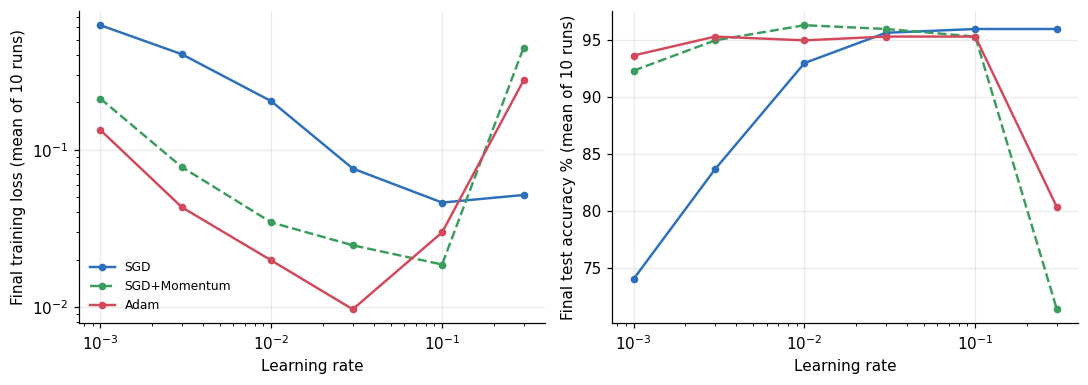

In [14]:
LRS = [0.001, 0.003, 0.01, 0.03, 0.1, 0.3]
sens = {n: {lr: [train(n, lr, split_seed=s, init_seed=s, epochs=EPOCHS, batch=BATCH) for s in range(10)] for lr in LRS}
        for n in OPTS}

acc_tbl = pd.DataFrame({n: {lr: np.mean([r["test_acc"][-1] for r in sens[n][lr]]) * 100 for lr in LRS} for n in OPTS})
acc_tbl.index.name = "learning rate"
display(acc_tbl.round(1))

fig, axs = plt.subplots(1, 2, figsize=(10, 3.6))
ls = {"SGD": "-", "Adam": "-", "SGD+Momentum": "--"}
for n in ["SGD", "SGD+Momentum", "Adam"]:
    tl = [np.mean([r["train_loss"][-1] for r in sens[n][lr]]) for lr in LRS]
    ta = [np.mean([r["test_acc"][-1] for r in sens[n][lr]]) * 100 for lr in LRS]
    axs[0].plot(LRS, tl, "o" + ls[n], color=COLORS[n], label=n, lw=1.6, ms=4)
    axs[1].plot(LRS, ta, "o" + ls[n], color=COLORS[n], label=n, lw=1.6, ms=4)
for a in axs: a.set_xscale("log"); a.set_xlabel("Learning rate")
axs[0].set_yscale("log"); axs[0].set_ylabel("Final training loss (mean of 10 runs)")
axs[1].set_ylabel("Final test accuracy % (mean of 10 runs)")
axs[0].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

## 5. Conclusions

*(Numbers below are from running this notebook with the seeds above.)*

1. **Adam trains much faster.** At the same learning rate (0.01) Adam reached a training loss of 0.1 in 10 epochs in the main run, while SGD had not reached it after 100. Across 20 runs Adam's final training loss was significantly lower (paired t-test, p < 0.001).
2. **The accuracy difference is small and not conclusive.** Adam averaged about 96.2% test accuracy versus 93.8% for SGD, but the gap is not statistically significant at the 5% level (p ≈ 0.09), and a 30-sample test set cannot resolve differences smaller than about 3 points.
3. **Much of SGD's disadvantage is a learning-rate effect.** SGD at η = 0.1 reaches about 96% mean test accuracy, matching or exceeding Adam at its best. Adam is easier to use because it performs well across a wider range of learning rates (0.001 to 0.1).
4. **SGD was still improving at epoch 100.** It was under-trained rather than stuck. Adding momentum closed most of the gap to Adam.
5. **Adam showed mild overfitting.** Its test loss bottoms out early and then creeps up while accuracy stays flat, so early stopping would help.
6. **All errors are between versicolor and virginica.** Setosa is classified (almost) perfectly by every optimizer.

**Overall:** on this problem the main difference between SGD and Adam is *convergence speed and ease of tuning*, not final accuracy.

### Limitations
Iris is small and easy; only one network size and batch size were tested; no regularisation, learning-rate schedule or early stopping was used; and the learning-rate study used test accuracy rather than a validation set.

### References
- Fisher, R. A. (1936). The use of multiple measurements in taxonomic problems. *Annals of Eugenics*, 7(2).
- Kingma, D. P., & Ba, J. (2015). Adam: A method for stochastic optimization. *ICLR*. arXiv:1412.6980.
- Robbins, H., & Monro, S. (1951). A stochastic approximation method. *Annals of Mathematical Statistics*, 22(3).
- Ruder, S. (2016). An overview of gradient descent optimization algorithms. arXiv:1609.04747.